# Prueba: agrupamiento propio de los productos en polvo
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Cuaderno **de prueba**, separado de `trabajo_senasa_mq.ipynb`. En el agrupamiento general los polvos quedan en tres tags:
**POLVO_GRASO** (leche en polvo entera), **POLVO_MAGRO** (todo lo demás: sueros, concentrados de suero, leche
descremada) y **PROT_ALTA** (caseínas y concentrados de más de 70 % de proteína). Acá se agrupan solo los polvos, para ver
si aparecen tipos reales dentro de esos tags y, si corresponde, proponer subtags `POLVO_<tipo>`. Es la misma prueba que
`prueba_clustering_quesos.ipynb`, con el mismo método y los mismos algoritmos.

**Qué es un polvo.** Las familias **leche en polvo**, **suero / permeado** y **concentrado proteico** con los cuatro
análisis (humedad, grasa, proteínas y cenizas; Senasa manda y MQ completa; MQ sale de `MQ encolumnado.xlsx`, sin las MO) y **humedad ≤ 15 g/100 g**. Hay un hueco
natural entre 12 y 25: lo que está arriba (humedad de 25 a 99) son sueros, permeados y concentrados **líquidos**, que no
son polvos.

**Criterio de variables (el mismo de los quesos).** En un polvo la humedad es de proceso (2 a 6 g/100 g) y lo que define
el tipo es **de qué están hechos los sólidos**. El espacio base es **grasa, proteína y cenizas en base seca** (g/100 g de
extracto seco): 3 dimensiones. La lactosa no entra: en base seca es casi exactamente 100 menos las otras tres (el
«resto por diferencia»), así que sería contar dos veces la misma información. La parametrización medida (humedad, grasa,
proteínas, cenizas) se prueba como control.

**Referencias para validar.** (1) El **tipo** del rótulo, independiente de lo medido: el subtipo (WPC, caseína,
caseinato, suero, suero desmineralizado, permeado, leche modificada...) y, en la leche en polvo, que casi nunca trae
subtipo, `desc_grasa` (entera, descremada). (2) La **familia**. (3) En la leche en polvo, la **clase de grasa del CAA**
(art. 567): es función de la grasa medida, así que no es una validación independiente.

El código está en `src/clustering_polvos.py`; se regenera con `build_prueba_polvos.py`. Escribe solo en
`resultados/prueba_polvos/`. Semilla 42. Al final, el **veredicto**.

## 0 · Rutas, parámetros y lectura

In [1]:
import sys
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, balanced_accuracy_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
import rutas as R
import clustering_polvos as P
from datos_clase41 import COLUMNAS, N_INIT_KMEDIAS, SEMILLA, leer_senasa

warnings.filterwarnings("ignore", message=".*covariance matrix.*full rank.*")
warnings.filterwarnings("ignore", message=".*Determinant has increased.*")
warnings.filterwarnings("ignore", message=".*y_pred contains classes not in y_true.*")
warnings.filterwarnings("ignore", message=".*least populated class.*")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
SALIDA = R.RESULTADOS / "prueba_polvos"; SALIDA.mkdir(parents=True, exist_ok=True)
PCT = 3                                   # corte de outliers por consenso (clase 46)
TAMANOS = (20, 30, 40, 50, 60)            # min_cluster_size de HDBSCAN
KS_KM, KS_GMM = range(2, 11), range(1, 13)
TIPO_MIN = 10                             # tipos con menos muestras no entran en la validación supervisada
DPI = 150

S = leer_senasa()
polvos, conteo = P.preparar_polvos(S)
pd.Series(conteo, name="muestras").to_frame()

,muestras
polvos leídos (las tres familias),9022
con los cuatro análisis,1340
excluidas: humedad + ST fuera de 100 ± 1,0
excluidas: suma de los cuatro > 102,1
"excluidas: humedad > 15 (líquidos, no polvo)",187
quedan,1152


## 1 · Conteos
Polvos por familia y origen. «Senasa completada con MQ»: muestra de Senasa a la que le faltaba algún análisis y lo
completó MQ. «solo MQ»: no está en Senasa y su familia sale de `mq_tipo_muestra.csv` (un desglose que **no se revisó a
mano**). La mayoría de las leches en polvo son solo MQ.

In [2]:
display(pd.crosstab(polvos["familia"], polvos["origen"], margins=True))
t = pd.crosstab(polvos["tipo"].fillna("sin tipo"), polvos["familia"], margins=True)
t.sort_values("All", ascending=False)

origen,Senasa,Senasa completada con MQ,solo MQ,All
familia,,,,
concentrado proteico,326,12,11,349
leche en polvo,100,66,513,679
suero / permeado,57,21,46,124
All,483,99,570,1152


familia,concentrado proteico,leche en polvo,suero / permeado,All
tipo,,,,
All,349,679,124,1152
LECHE ENTERA,0,523,0,523
WPC,292,0,0,292
LECHE DESCREMADA,0,74,0,74
SUERO DESMINERALIZADO,0,0,65,65
LECHE MODIFICADA,0,49,0,49
sin tipo,12,32,4,48
SUERO,0,0,40,40
CASEINATO,26,0,0,26


**Los líquidos que quedan afuera** (humedad > 15): por familia y subtipo, con su humedad mediana.

In [3]:
from datos_clase41 import leer_mq, unir
_, mq_ = leer_mq()
sen_ = S.crudo[["Identificador", "desc_familia", "desc_subtipo"] + COLUMNAS]
tipo_mq_ = pd.read_csv(R.MQ_TIPO).drop_duplicates("codigo").set_index("codigo")
u_, _ = unir(sen_, mq_)
u_["desc_familia"] = u_["desc_familia"].where(u_["origen"] != "solo MQ", u_["Identificador"].map(tipo_mq_["desc_familia"]))
liq = u_[u_["desc_familia"].isin(P.FAMILIAS)].dropna(subset=COLUMNAS).query("humedad > @P.HUMEDAD_MAX")
print(f"humedad de los polvos: hasta {polvos['humedad'].max():.1f} · humedad de los líquidos: de {liq['humedad'].min():.1f} a {liq['humedad'].max():.1f} (n = {len(liq)})")
liq.groupby(["desc_familia", liq["desc_subtipo"].fillna("sin subtipo")]).agg(
    muestras=("Identificador", "size"), humedad=("humedad", "median"), proteinas=("proteinas", "median")).round(1)

humedad de los polvos: hasta 11.8 · humedad de los líquidos: de 25.0 a 99.4 (n = 188)


muestras  humedad  proteinas
desc_familia         desc_subtipo                                   
concentrado proteico WPC                      23     89.2        6.6
                     sin subtipo              18     91.2        3.3
leche en polvo       sin subtipo               2     46.3       18.2
suero / permeado     CONCENTRADO               8     85.3        2.1
                     DESMINERALIZADO           1     83.6        3.6
                     PERMEADO                  5     84.7        0.3
                     PERMEADO DE LECHE        22     89.7        0.3
                     PERMEADO DE SUERO        42     95.2        0.2
                     SUERO                    23     94.7        0.8
                     sin subtipo              44     84.0        2.2

## 2 · Parametrización del espacio base
* **Base seca (grasa, proteína, cenizas en g/100 g de extracto seco).** Saca la humedad, que en un polvo es de proceso y
  no del tipo, y deja la composición de los sólidos. El «resto» (100 − las tres) es casi todo lactosa.
* **Lo medido (humedad, grasa, proteínas, cenizas).** Lo que usa el agrupamiento general. Se repite todo así en la
  sección 3.4.

¿Hace falta la lactosa como variable? Se compara la lactosa medida con el resto por diferencia, en las muestras que la
tienen.

In [4]:
display(polvos[P.BASE + ["resto_bs"]].corr().round(2))
q = polvos.dropna(subset=["lactosa"])
igual = (q["resto_bs"] - q["lactosa_bs"]).abs() < 0.05
print(f"con lactosa medida: {len(q)} (origen: {q['origen'].value_counts().to_dict()})")
print(f"r de Pearson lactosa (base seca) vs resto por diferencia: {np.corrcoef(q['lactosa_bs'], q['resto_bs'])[0, 1]:.3f}")
print(f"lactosa = resto por diferencia (±0,05): {igual.sum()} de {len(q)}")
q.loc[~igual, ["Identificador", "tipo", "lactosa_bs", "resto_bs"]].round(1).sort_values("tipo")

,grasa_bs,proteina_bs,cenizas_bs,resto_bs
grasa_bs,1.00,-0.40,-0.14,-0.41
proteina_bs,-0.40,1.00,0.02,-0.67
cenizas_bs,-0.14,0.02,1.00,0.02
resto_bs,-0.41,-0.67,0.02,1.00


con lactosa medida: 95 (origen: {'Senasa completada con MQ': 95})
r de Pearson lactosa (base seca) vs resto por diferencia: 0.988
lactosa = resto por diferencia (±0,05): 74 de 95


,Identificador,tipo,lactosa_bs,resto_bs
533,MQ-42919-01,LECHE DESCREMADA,39.4,51.2
529,MQ-42679-04,LECHE DESCREMADA,55.3,54.3
516,MQ-41840-03,LECHE DESCREMADA,38.2,50.8
494,MQ-40480-05,LECHE DESCREMADA,55.9,55.8
486,MQ-40299-02,LECHE ENTERA,41.5,40.9
504,MQ-41041-01,LECHE ENTERA,43.0,40.9
489,MQ-40299-05,LECHE ENTERA,40.3,40.2
488,MQ-40299-04,LECHE ENTERA,41.7,41.6
487,MQ-40299-03,LECHE ENTERA,41.2,41.2
523,MQ-42519-01,MPC,19.9,20.0


La lactosa informada en estos polvos es, en la mayoría, **el resto por diferencia** (coincide dentro de ±0,05). No es un análisis independiente y son pocas muestras: **no hay nivel extendido** en los polvos (en los
quesos lo daban NaCl, proteína y cenizas de MQ; acá ya están todos en la base).

## 3 · Nivel base: grasa, proteína y cenizas en base seca
### 3.1 · Outliers por consenso
`mejoras_clustering.outliers_consenso`: factor local (LOF, 50 vecinos), bosque de aislamiento y elipse, cada uno marca el
3 % de menor puntaje; outlier si lo marcan al menos 2 de 3. Todos los polvos son un solo grupo.

In [5]:
X_todas = P.matriz(polvos, P.BASE)
es_out, votos = P.quitar_outliers(X_todas, pct=PCT)
base = polvos[~es_out].reset_index(drop=True)
print(f"outliers: {es_out.sum()} de {len(polvos)} ({100 * es_out.mean():.1f} %); quedan {len(base)}")
print("por tipo:", polvos.loc[es_out, "tipo"].fillna("sin tipo").value_counts().to_dict())
polvos.loc[es_out, ["Identificador", "Cliente", "familia", "tipo", "humedad"] + P.BASE].round(1).sort_values(["tipo", "proteina_bs"])

outliers: 22 de 1152 (1.9 %); quedan 1130
por tipo: {'SUERO DESMINERALIZADO': 6, 'SUERO': 5, 'CASEINA': 4, 'SUERO REENGRASADO': 3, 'sin tipo': 3, 'WPC': 1}


,Identificador,Cliente,familia,tipo,humedad,grasa_bs,proteina_bs,cenizas_bs
223,MO-09196-01,IND-109,concentrado proteico,CASEINA,11.3,2.1,95.3,2.1
79,MO-08008-01,IND-109,concentrado proteico,CASEINA,11.8,1.7,95.9,2.1
170,MO-08734-01,IND-109,concentrado proteico,CASEINA,11.2,2.1,96.3,2.1
109,MO-08403-01,IND-109,concentrado proteico,CASEINA,11.7,2.0,96.7,2.3
104,MO-08311-01,IND-104,suero / permeado,SUERO,1.8,49.4,5.8,2.8
396,MO-10685-01,IND-104,suero / permeado,SUERO,1.8,50.8,6.0,2.8
248,MO-09414-01,IND-104,suero / permeado,SUERO,1.6,50.4,6.2,2.6
177,MO-08808-01,IND-104,suero / permeado,SUERO,2.8,25.0,8.5,4.1
36,MO-07734-01,IND-104,suero / permeado,SUERO,2.3,25.8,9.5,4.1
148,MO-08633-02,IND-33,suero / permeado,SUERO DESMINERALIZADO,2.2,0.9,13.8,0.8


Casi todos los outliers son **tipos reales con pocas muestras**: suero y suero reengrasado con grasa de 25 a 56 % en
base seca (8 muestras), caseína ácida (4; humedad ≈ 11), suero desmineralizado con cenizas < 1 (6) y dos concentrados con
83 % de proteína (uno sin tipo). Hay además dos permeados sin tipo con cenizas de 19 a 23 en base seca, que podrían ser
un error de carga. Quedan fuera del agrupamiento por ser pocos; el CSV los conserva marcados.

### 3.2 · Los tres algoritmos
* **k-medias**: k por silueta máxima (2 a 10).
* **Mezcla de gaussianas** (covarianza completa, n_init 3): k por BIC mínimo (1 a 12).
* **HDBSCAN**: min_cluster_size 20 a 60, elegido *sin mirar las referencias* (el número de grupos más frecuente en la
  grilla y, entre los que lo dan, el menor tamaño).

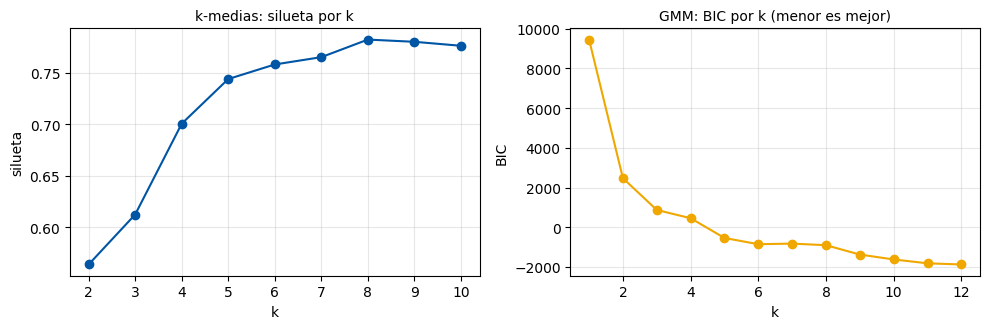

In [6]:
def correr(d, variables):
    # Los tres algoritmos sobre d[variables] escalado; etiquetas renumeradas por proteína en base seca
    Z, _ = P.escalar(P.matriz(d, variables))
    km, k_km, sil, _ = P.kmedias(Z, KS_KM)
    gm, k_gm, bic, mod = P.mezcla(Z, KS_GMM)
    hd = P.hdbscan_sensibilidad(Z, TAMANOS)
    m_hd, e_hd = P.elegir_hdbscan(hd)
    pr = d["proteina_bs"].to_numpy()
    et = {f"k-medias (k = {k_km})": P.ordenar(km, pr), f"GMM (k = {k_gm}, BIC)": P.ordenar(gm, pr),
          f"HDBSCAN (min {m_hd})": P.ordenar(e_hd, pr)}
    return dict(Z=Z, et=et, sil=sil, bic=bic, hd=hd, m_hd=m_hd, gmm=mod, k_km=k_km, k_gm=k_gm)

def referencias(d):
    return {"tipo": d["tipo"], "familia": d["familia"]}

tg = P.tags_generales()
base = base.join(tg, on="Identificador")

def tabla(r, d, extra=True):
    filas = {n: P.evaluar(r["Z"], e, referencias(d)) for n, e in r["et"].items()}
    if extra:   # vara: los tags del agrupamiento general (Senasa + MQ) como partición de estas mismas muestras
        filas["tags del agrupamiento general"] = P.evaluar(r["Z"], pd.factorize(d["tag_senasa_mq"].fillna("no está"))[0], referencias(d))
    return pd.DataFrame(filas).T

rb = correr(base, P.BASE)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(list(rb["sil"]), list(rb["sil"].values()), "o-", color=P.PALETA[0]); ax[0].set_xlabel("k"); ax[0].set_ylabel("silueta")
ax[0].set_title("k-medias: silueta por k", fontsize=10)
ax[1].plot(list(rb["bic"]), list(rb["bic"].values()), "o-", color=P.PALETA[1]); ax[1].set_xlabel("k"); ax[1].set_ylabel("BIC")
ax[1].set_title("GMM: BIC por k (menor es mejor)", fontsize=10)
for a in ax: a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(SALIDA / "base_seleccion_k.png", dpi=DPI); plt.show()

**Sensibilidad de HDBSCAN a min_cluster_size:**

In [7]:
filas = {}
for m, e in rb["hd"].items():
    f = P.evaluar(rb["Z"], e, referencias(base))
    filas[m] = {k: f[k] for k in ["grupos", "ruido", "silueta", "silueta macro", "ARI tipo", "ARI familia"]}
pd.DataFrame(filas).T.rename_axis("min_cluster_size").round(3)

,grupos,ruido,silueta,silueta macro,ARI tipo,ARI familia
min_cluster_size,,,,,,
20,7.0,84.0,0.827,0.761,0.760,0.685
30,6.0,107.0,0.842,0.788,0.754,0.681
40,5.0,151.0,0.848,0.805,0.748,0.687
50,5.0,154.0,0.850,0.809,0.747,0.686
60,5.0,159.0,0.853,0.816,0.746,0.686


**Métricas y acuerdo con las referencias.** Silueta, Davies-Bouldin y Calinski-Harabasz sin el ruido; ARI y NMI contando
el ruido de HDBSCAN como un grupo más. La última fila no es un agrupamiento de esta prueba: son los tags del
agrupamiento general (POLVO_GRASO, POLVO_MAGRO, PROT_ALTA) sobre las mismas muestras, como vara para saber si agrupar
solo los polvos agrega algo.

In [8]:
tb = tabla(rb, base)
tb.round(3)

,grupos,ruido,silueta,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,ARI tipo,NMI tipo,ARI familia,NMI familia
k-medias (k = 8),8.0,0.0,0.782,0.731,0.548,0.369,3075.243,0.756,0.726,0.679,0.602
"GMM (k = 12, BIC)",12.0,0.0,0.450,0.486,-0.241,0.940,2053.605,0.564,0.673,0.396,0.519
HDBSCAN (min 40),5.0,151.0,0.848,0.805,0.676,0.250,7011.727,0.748,0.710,0.687,0.650
tags del agrupamiento general,4.0,0.0,0.638,0.448,0.146,0.963,714.474,0.696,0.668,0.618,0.526


### 3.3 · Qué hay en cada cluster
Centroides en g/100 g de extracto seco (humedad en g/100 g); tipo, familia y clase CAA de la leche mayoritarios con su
pureza (% sobre las muestras del cluster que tienen ese dato) y, para el tipo, su cobertura (% de ese tipo que cae en el
cluster). Clusters numerados por proteína en base seca creciente.

In [9]:
for n, e in rb["et"].items():
    print(n); display(P.describir(base, e))

k-medias (k = 8)


,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,resto_bs,humedad,tipo mayoritario,% tipo,con tipo,% cobertura tipo,familia mayoritario,% familia,CAA leche mayoritario,% CAA leche
cluster,,,,,,,,,,,,,,,
0,80,10,2.1,11.9,5.0,81.0,2.8,SUERO DESMINERALIZADO,68.0,78,90,suero / permeado,96.0,parcialmente descremada,100.0
1,5,1,1.1,14.0,0.9,84.0,2.4,SUERO DESMINERALIZADO,100.0,5,8,suero / permeado,100.0,-,NaN
2,605,21,28.1,26.7,5.8,39.4,2.8,LECHE ENTERA,90.0,577,100,leche en polvo,99.0,entera,96.0
3,167,8,3.5,37.0,6.4,53.1,4.0,WPC,94.0,167,54,concentrado proteico,95.0,parcialmente descremada,100.0
4,100,4,3.8,37.4,5.3,53.5,4.0,WPC,99.0,100,34,concentrado proteico,100.0,-,NaN
5,114,14,2.6,37.7,8.0,51.7,3.9,LECHE DESCREMADA,64.0,112,97,leche en polvo,64.0,descremada,95.0
6,18,4,2.6,78.1,7.9,11.3,6.6,CASEINA,36.0,14,100,concentrado proteico,61.0,parcialmente descremada,80.0
7,41,4,2.7,89.6,3.9,3.8,5.4,CASEINATO,81.0,32,100,concentrado proteico,98.0,-,NaN


GMM (k = 12, BIC)


,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,resto_bs,humedad,tipo mayoritario,% tipo,con tipo,% cobertura tipo,familia mayoritario,% familia,CAA leche mayoritario,% CAA leche
cluster,,,,,,,,,,,,,,,
0,81,10,2.1,12.0,5.0,80.9,2.8,SUERO DESMINERALIZADO,68.0,79,92,suero / permeado,96.0,parcialmente descremada,100.0
1,5,1,1.1,14.0,0.9,84.0,2.4,SUERO DESMINERALIZADO,100.0,5,8,suero / permeado,100.0,-,NaN
2,207,20,27.8,25.6,5.8,40.8,3.0,LECHE ENTERA,72.0,185,26,leche en polvo,98.0,entera,90.0
3,389,11,28.3,27.4,5.8,38.5,2.7,LECHE ENTERA,99.0,383,73,leche en polvo,100.0,entera,100.0
4,45,9,10.5,31.2,7.2,51.2,3.7,SUERO,40.0,45,51,leche en polvo,47.0,descremada,62.0
5,31,4,3.8,36.2,6.1,53.9,3.8,WPC,100.0,31,11,concentrado proteico,100.0,-,NaN
6,95,1,3.8,36.8,5.3,54.2,4.0,WPC,100.0,95,33,concentrado proteico,100.0,-,NaN
7,125,1,2.9,37.7,6.5,53.0,4.1,WPC,100.0,125,43,concentrado proteico,100.0,-,NaN
8,89,11,1.9,38.8,8.1,51.2,3.9,LECHE DESCREMADA,68.0,87,80,leche en polvo,67.0,descremada,93.0


HDBSCAN (min 40)


,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,resto_bs,humedad,tipo mayoritario,% tipo,con tipo,% cobertura tipo,familia mayoritario,% familia,CAA leche mayoritario,% CAA leche
cluster,,,,,,,,,,,,,,,
0,79,9,1.9,11.9,5.0,81.2,2.8,SUERO DESMINERALIZADO,68.0,78,90,suero / permeado,97.0,-,NaN
1,599,21,28.1,26.8,5.8,39.3,2.8,LECHE ENTERA,91.0,571,99,leche en polvo,100.0,entera,96.0
2,69,12,1.3,36.4,8.1,54.2,3.8,LECHE DESCREMADA,93.0,68,85,leche en polvo,93.0,descremada,94.0
3,83,1,3.8,36.6,5.4,54.3,4.1,WPC,100.0,83,29,concentrado proteico,100.0,-,NaN
4,149,4,3.0,37.4,6.4,53.2,4.1,WPC,100.0,149,51,concentrado proteico,100.0,-,NaN
ruido,151,16,5.0,55.4,6.0,33.6,4.6,WPC,40.0,136,19,concentrado proteico,69.0,descremada,59.0


In [10]:
for n, e in rb["et"].items():
    print(n, "· tipo del rótulo (filas) × cluster (columnas)")
    display(pd.crosstab(base["tipo"].fillna("sin tipo"), np.where(e == -1, "ruido", e.astype(str))))

k-medias (k = 8) · tipo del rótulo (filas) × cluster (columnas)


col_0,0,1,2,3,4,5,6,7
tipo,,,,,,,,
CASEINA,0,0,0,0,0,0,5,0
CASEINATO,0,0,0,0,0,0,0,26
LECHE DESCREMADA,0,0,1,1,0,72,0,0
LECHE ENTERA,0,0,521,0,0,0,2,0
LECHE MODIFICADA,0,0,49,0,0,0,0,0
LECHE PARCIALMENTE DESCREMADA,0,0,0,0,0,1,0,0
MPC,0,0,1,0,0,0,3,0
PERMEADO,11,0,0,0,0,0,0,0
PROTEINAS LACTEAS,2,0,0,1,1,0,0,2


GMM (k = 12, BIC) · tipo del rótulo (filas) × cluster (columnas)


col_0,0,1,10,11,2,3,4,5,6,7,8,9
tipo,,,,,,,,,,,,
CASEINA,0,0,0,0,0,0,0,0,0,0,0,5
CASEINATO,0,0,0,26,0,0,0,0,0,0,0,0
LECHE DESCREMADA,0,0,0,0,1,0,14,0,0,0,59,0
LECHE ENTERA,0,0,0,0,134,380,7,0,0,0,0,2
LECHE MODIFICADA,0,0,0,0,46,3,0,0,0,0,0,0
LECHE PARCIALMENTE DESCREMADA,0,0,0,0,0,0,0,0,0,0,1,0
MPC,0,0,0,0,1,0,0,0,0,0,0,3
PERMEADO,11,0,0,0,0,0,0,0,0,0,0,0
PROTEINAS LACTEAS,2,0,3,0,0,0,0,0,0,0,0,1


HDBSCAN (min 40) · tipo del rótulo (filas) × cluster (columnas)


col_0,0,1,2,3,4,ruido
tipo,,,,,,
CASEINA,0,0,0,0,0,5
CASEINATO,0,0,0,0,0,26
LECHE DESCREMADA,0,1,63,0,0,10
LECHE ENTERA,0,520,0,0,0,3
LECHE MODIFICADA,0,49,0,0,0,0
LECHE PARCIALMENTE DESCREMADA,0,0,1,0,0,0
MPC,0,0,0,0,0,4
PERMEADO,11,0,0,0,0,0
PROTEINAS LACTEAS,2,0,0,0,0,4


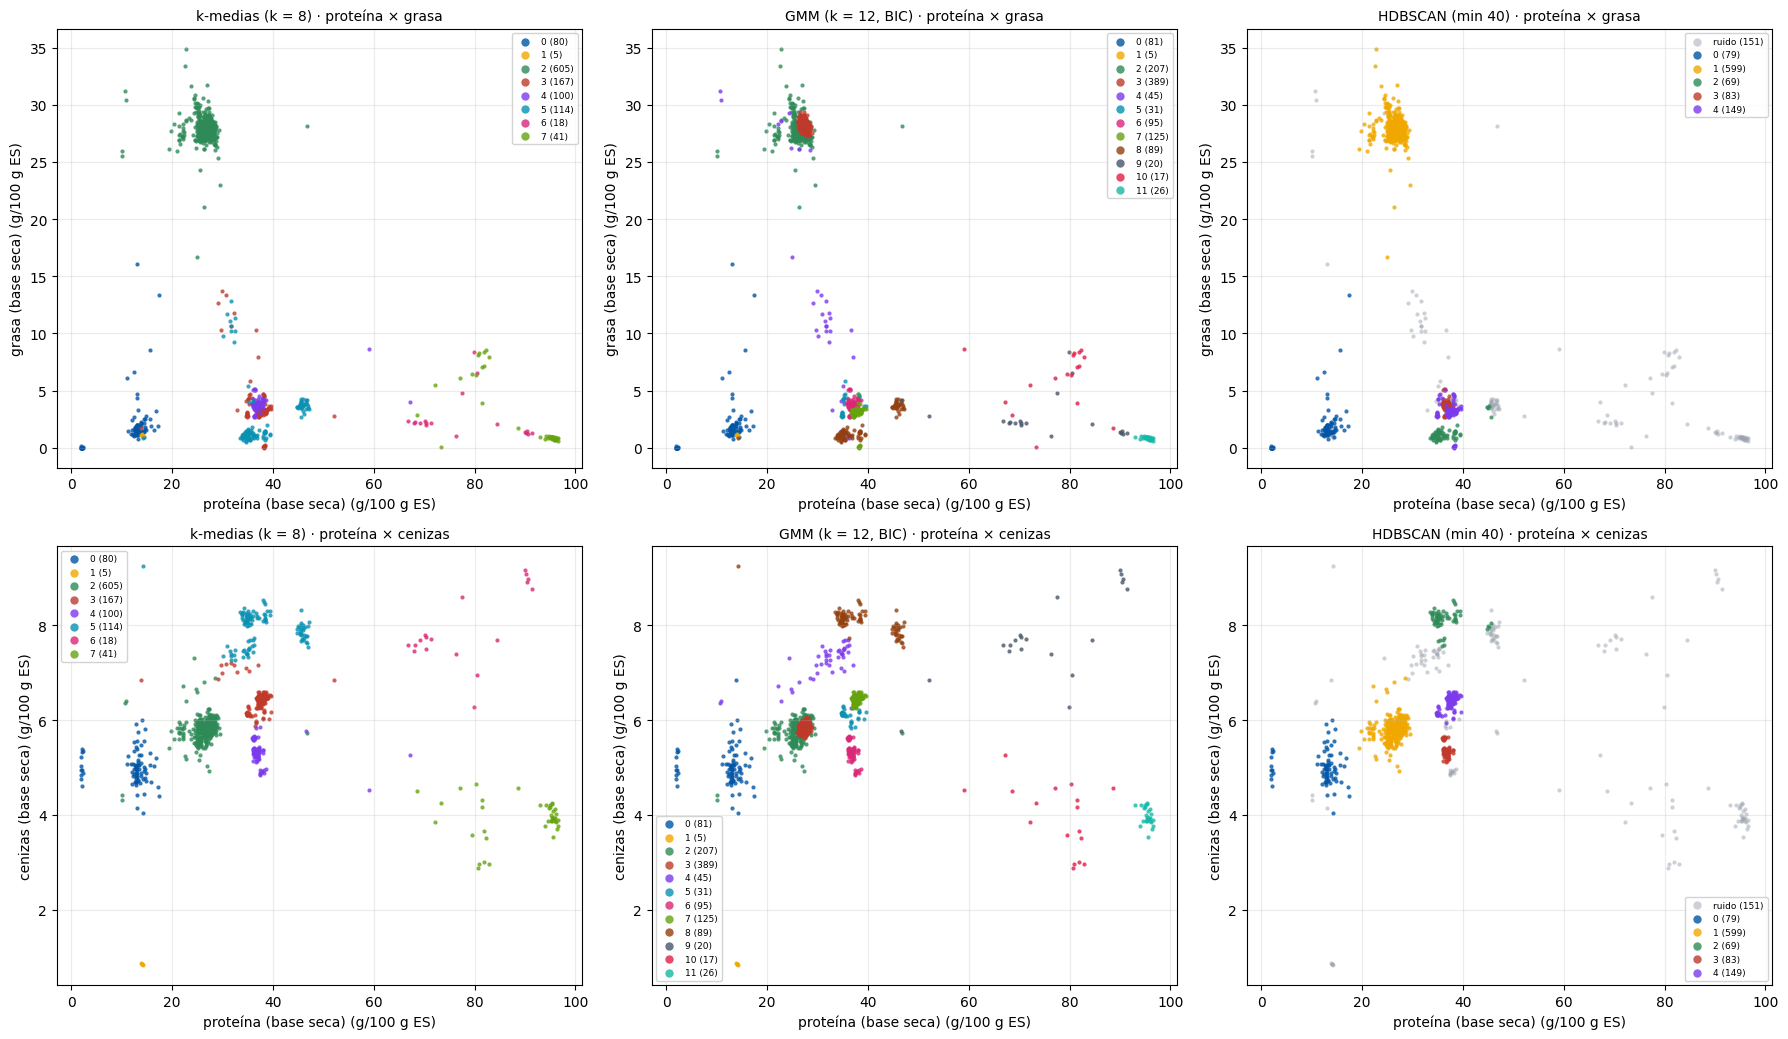

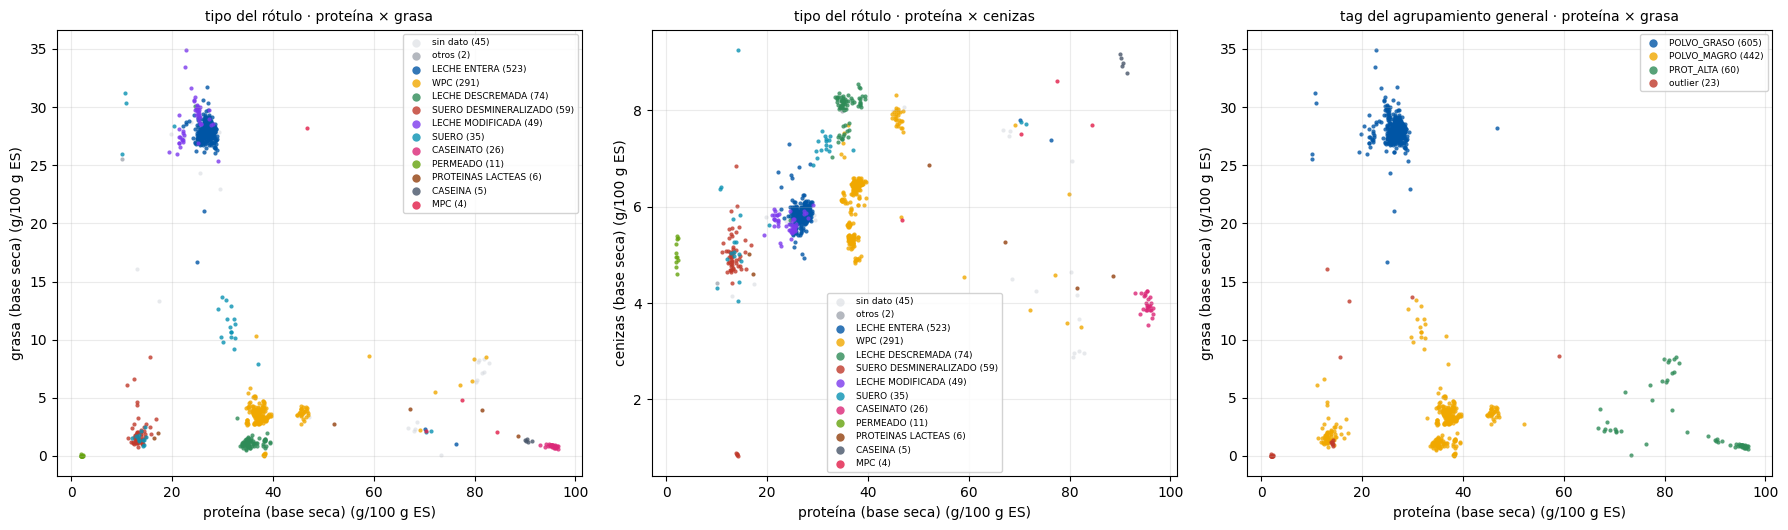

In [11]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10.5))
for j, (n, e) in enumerate(rb["et"].items()):
    d = base.assign(cl=np.where(e == -1, "ruido", e.astype(str)))
    orden = sorted(set(d["cl"]) - {"ruido"}, key=int)
    P.dispersion(axs[0, j], d, "cl", f"{n} · proteína × grasa", max_cat=12, orden=orden)
    P.dispersion(axs[1, j], d, "cl", f"{n} · proteína × cenizas", y="cenizas_bs", max_cat=12, orden=orden)
fig.tight_layout(); fig.savefig(SALIDA / "base_clusters.png", dpi=DPI); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(18, 5.4))
P.dispersion(axs[0], base, "tipo", "tipo del rótulo · proteína × grasa", max_cat=11)
P.dispersion(axs[1], base, "tipo", "tipo del rótulo · proteína × cenizas", y="cenizas_bs", max_cat=11)
P.dispersion(axs[2], base, "tag_senasa_mq", "tag del agrupamiento general · proteína × grasa", max_cat=4)
fig.tight_layout(); fig.savefig(SALIDA / "base_referencias.png", dpi=DPI); plt.show()

### 3.4 · ¿Depende de la parametrización? Lo mismo con lo medido
Mismas muestras (los mismos outliers), escaladas en humedad, grasa, proteínas y cenizas (g/100 g). Se compara cada
algoritmo con su par de la sección 3.2 (ARI entre las dos particiones: 1 = idénticas).

In [12]:
ra = correr(base, P.BASE_ALT)
ta = tabla(ra, base, extra=False)
n_grupos = lambda r: [len(set(e) - {-1}) for e in r["et"].values()]
comp = pd.DataFrame({
    "k (base seca)": n_grupos(rb), "k (medido)": n_grupos(ra),
    "ARI tipo (base seca)": tb["ARI tipo"].iloc[:3].values, "ARI tipo (medido)": ta["ARI tipo"].values,
    "silueta (base seca)": tb["silueta"].iloc[:3].values, "silueta (medido)": ta["silueta"].values,
    "ARI entre parametrizaciones": [adjusted_rand_score(a, b) for a, b in zip(rb["et"].values(), ra["et"].values())]},
    index=["k-medias", "GMM", "HDBSCAN"])
display(comp.round(3))
n_km_a = list(ra["et"])[0]
print(n_km_a); display(P.describir(base, ra["et"][n_km_a], cols=("humedad", "grasa", "proteinas", "cenizas")))

,k (base seca),k (medido),ARI tipo (base seca),ARI tipo (medido),silueta (base seca),silueta (medido),ARI entre parametrizaciones
k-medias,8,7,0.756,0.809,0.782,0.666,0.923
GMM,12,12,0.564,0.559,0.450,0.386,0.830
HDBSCAN,5,7,0.748,0.732,0.848,0.727,0.933


k-medias (k = 7)


,muestras,clientes,humedad,grasa,proteinas,cenizas,tipo mayoritario,% tipo,con tipo,% cobertura tipo,familia mayoritario,% familia,CAA leche mayoritario,% CAA leche
cluster,,,,,,,,,,,,,,
0,79,9,2.7,2.0,11.6,4.9,SUERO DESMINERALIZADO,70.0,77,92,suero / permeado,96.0,parcialmente descremada,100.0
1,5,1,2.4,1.1,13.7,0.8,SUERO DESMINERALIZADO,100.0,5,8,suero / permeado,100.0,-,NaN
2,603,21,2.8,27.3,26.0,5.6,LECHE ENTERA,90.0,575,99,leche en polvo,99.0,entera,96.0
3,261,9,4.1,3.5,35.5,5.7,WPC,97.0,261,87,concentrado proteico,98.0,parcialmente descremada,50.0
4,134,15,4.0,2.8,38.7,7.6,LECHE DESCREMADA,57.0,129,99,leche en polvo,59.0,descremada,89.0
5,43,4,5.4,2.8,84.3,3.8,CASEINATO,79.0,33,100,concentrado proteico,98.0,-,NaN
6,5,1,10.9,1.2,80.7,8.0,CASEINA,100.0,5,100,concentrado proteico,100.0,-,NaN


### 3.5 · Estabilidad
k-medias y la mezcla con otras semillas (k fijo en el elegido), y el BIC de la mezcla hasta k = 16 (solo para ver la forma).

In [13]:
n_km = list(rb["et"])[0]; n_gm = list(rb["et"])[1]; n_hd = list(rb["et"])[2]
k_km, k_gm = rb["k_km"], rb["k_gm"]
pr = base["proteina_bs"]
otras_km = {s: P.ordenar(KMeans(n_clusters=k_km, n_init=N_INIT_KMEDIAS, random_state=s).fit_predict(rb["Z"]), pr) for s in range(SEMILLA + 1, SEMILLA + 6)}
otras_gm = {s: P.ordenar(GaussianMixture(n_components=k_gm, n_init=3, random_state=s).fit(rb["Z"]).predict(rb["Z"]), pr)
            for s in range(SEMILLA + 1, SEMILLA + 6)}
print("k-medias · ARI contra la semilla 42:", {s: round(adjusted_rand_score(rb["et"][n_km], e), 2) for s, e in otras_km.items()})
print("GMM · ARI contra la semilla 42:", {s: round(adjusted_rand_score(rb["et"][n_gm], e), 2) for s, e in otras_gm.items()})
bic_largo = {k: GaussianMixture(n_components=k, n_init=3, random_state=SEMILLA).fit(rb["Z"]).bic(rb["Z"]) for k in range(8, 17)}
print("BIC k = 8..16:", {k: round(v) for k, v in bic_largo.items()})

k-medias · ARI contra la semilla 42: {43: 1.0, 44: 1.0, 45: 1.0, 46: 1.0, 47: 1.0}
GMM · ARI contra la semilla 42: {43: 0.65, 44: 0.66, 45: 0.88, 46: 0.65, 47: 0.66}


BIC k = 8..16: {8: -907, 9: -1378, 10: -1625, 11: -1820, 12: -1878, 13: -2019, 14: -2236, 15: -2232, 16: -2490}


### 3.6 · ¿Los clusters son tipos o clientes?
Con pocos clientes por tipo, un cluster puede ser la receta de un cliente y no un tipo de producto (pasó con el DDL
repostero de IND-51). Tabla cruzada cluster × cliente (clientes con al menos 15 muestras; «sin cliente» = sin dato).

In [14]:
e = rb["et"][n_km]
cli = base["Cliente"].fillna("sin cliente")
t = pd.crosstab(pd.Series(e, name="cluster k-medias"), cli)
display(t.loc[:, t.sum() >= 15])
wpc = base["tipo"].eq("WPC")
print("WPC por cliente y cluster:"); display(pd.crosstab(cli[wpc].to_numpy(), e[wpc], rownames=["Cliente"], colnames=["cluster"]))
display(base[wpc].groupby(cli[wpc])[["proteina_bs", "grasa_bs", "cenizas_bs", "humedad"]].median().round(2))

Cliente,IND-06,IND-103,IND-104,IND-109,IND-11,IND-115,IND-30,IND-38,IND-47,IND-59,IND-68,IND-70,IND-89,IND-93,IND-99
cluster k-medias,,,,,,,,,,,,,,,
0,0,2,4,0,0,0,46,0,0,0,0,13,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,9,18,9,27,13,2,44,27,16,3,0,15,12,377
3,134,0,1,8,0,9,1,6,0,0,5,1,0,0,0
4,1,0,0,0,0,1,0,0,0,0,95,2,0,0,0
5,0,7,1,2,0,4,0,22,0,15,4,28,15,4,0
6,2,0,0,5,0,9,0,0,0,0,0,2,0,0,0
7,3,0,1,0,0,0,0,0,0,0,0,35,0,0,0


WPC por cliente y cluster:


cluster,3,4,5,6,7
Cliente,,,,,
IND-06,134,1,0,0,3
IND-109,8,0,2,0,0
IND-115,8,1,1,1,0
IND-68,5,95,0,0,0
IND-70,0,1,26,1,0
sin cliente,2,1,0,0,1


,proteina_bs,grasa_bs,cenizas_bs,humedad
Cliente,,,,
IND-06,37.40,3.09,6.46,4.14
IND-109,35.22,4.28,6.29,4.16
IND-115,38.24,4.41,6.18,4.04
IND-68,36.61,3.81,5.32,4.03
IND-70,45.93,3.73,7.82,4.30
sin cliente,38.08,4.71,5.63,4.24


## 4 · Subtags
Regla (`clustering_polvos.proponer_subtags`): un cluster lleva subtag solo si corresponde a un tipo real:
1. **tipo** del rótulo con pureza ≥ 70 % (con ≥ 20 muestras con tipo, que sean al menos la mitad del cluster) y
   **cobertura** ≥ 50 % del tipo, sumando los clusters puros de ese tipo (un tipo puede ocupar dos regiones, como el WPC
   de dos clientes) → `POLVO_<TIPO>`;
2. si no, **familia** con pureza ≥ 70 % → `POLVO_LECHE`, `POLVO_SUERO_PERMEADO`, `POLVO_CONCENTRADO`.

Se aplica a los tres algoritmos del nivel base.

In [15]:
props = {}
for n, e in rb["et"].items():
    desc = P.describir(base, e)
    p = P.proponer_subtags(desc)
    props[n] = p
    print(n); display(desc[["muestras", "clientes", "grasa_bs", "proteina_bs", "cenizas_bs", "tipo mayoritario", "% tipo",
                            "% cobertura tipo", "familia mayoritario", "% familia"]].join(p[["subtag", "criterio", "% cobertura"]])
                      .fillna({"subtag": "POLVO"}))

k-medias (k = 8)


,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,tipo mayoritario,% tipo,% cobertura tipo,familia mayoritario,% familia,subtag,criterio,% cobertura
cluster,,,,,,,,,,,,,
0,80,10,2.1,11.9,5.0,SUERO DESMINERALIZADO,68.0,90,suero / permeado,96.0,POLVO_SUERO_PERMEADO,familia,NaN
1,5,1,1.1,14.0,0.9,SUERO DESMINERALIZADO,100.0,8,suero / permeado,100.0,POLVO_SUERO_PERMEADO,familia,NaN
2,605,21,28.1,26.7,5.8,LECHE ENTERA,90.0,100,leche en polvo,99.0,POLVO_LECHE_ENTERA,tipo,100.0
3,167,8,3.5,37.0,6.4,WPC,94.0,54,concentrado proteico,95.0,POLVO_WPC,tipo,88.0
4,100,4,3.8,37.4,5.3,WPC,99.0,34,concentrado proteico,100.0,POLVO_WPC,tipo,88.0
5,114,14,2.6,37.7,8.0,LECHE DESCREMADA,64.0,97,leche en polvo,64.0,POLVO,NaN,NaN
6,18,4,2.6,78.1,7.9,CASEINA,36.0,100,concentrado proteico,61.0,POLVO,NaN,NaN
7,41,4,2.7,89.6,3.9,CASEINATO,81.0,100,concentrado proteico,98.0,POLVO_CASEINATO,tipo,100.0


GMM (k = 12, BIC)


,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,tipo mayoritario,% tipo,% cobertura tipo,familia mayoritario,% familia,subtag,criterio,% cobertura
cluster,,,,,,,,,,,,,
0,81,10,2.1,12.0,5.0,SUERO DESMINERALIZADO,68.0,92,suero / permeado,96.0,POLVO_SUERO_PERMEADO,familia,NaN
1,5,1,1.1,14.0,0.9,SUERO DESMINERALIZADO,100.0,8,suero / permeado,100.0,POLVO_SUERO_PERMEADO,familia,NaN
2,207,20,27.8,25.6,5.8,LECHE ENTERA,72.0,26,leche en polvo,98.0,POLVO_LECHE_ENTERA,tipo,99.0
3,389,11,28.3,27.4,5.8,LECHE ENTERA,99.0,73,leche en polvo,100.0,POLVO_LECHE_ENTERA,tipo,99.0
4,45,9,10.5,31.2,7.2,SUERO,40.0,51,leche en polvo,47.0,POLVO,NaN,NaN
5,31,4,3.8,36.2,6.1,WPC,100.0,11,concentrado proteico,100.0,POLVO_WPC,tipo,87.0
6,95,1,3.8,36.8,5.3,WPC,100.0,33,concentrado proteico,100.0,POLVO_WPC,tipo,87.0
7,125,1,2.9,37.7,6.5,WPC,100.0,43,concentrado proteico,100.0,POLVO_WPC,tipo,87.0
8,89,11,1.9,38.8,8.1,LECHE DESCREMADA,68.0,80,leche en polvo,67.0,POLVO,NaN,NaN


HDBSCAN (min 40)


,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,tipo mayoritario,% tipo,% cobertura tipo,familia mayoritario,% familia,subtag,criterio,% cobertura
cluster,,,,,,,,,,,,,
0,79,9,1.9,11.9,5.0,SUERO DESMINERALIZADO,68.0,90,suero / permeado,97.0,POLVO_SUERO_PERMEADO,familia,NaN
1,599,21,28.1,26.8,5.8,LECHE ENTERA,91.0,99,leche en polvo,100.0,POLVO_LECHE_ENTERA,tipo,99.0
2,69,12,1.3,36.4,8.1,LECHE DESCREMADA,93.0,85,leche en polvo,93.0,POLVO_LECHE_DESCREMADA,tipo,85.0
3,83,1,3.8,36.6,5.4,WPC,100.0,29,concentrado proteico,100.0,POLVO_WPC,tipo,80.0
4,149,4,3.0,37.4,6.4,WPC,100.0,51,concentrado proteico,100.0,POLVO_WPC,tipo,80.0
ruido,151,16,5.0,55.4,6.0,WPC,40.0,19,concentrado proteico,69.0,POLVO,NaN,NaN


In [16]:
st_km = P.subtag_por_muestra(rb["et"][n_km], props[n_km])
res = pd.DataFrame({"subtag": st_km, "tipo": base["tipo"].fillna("sin tipo")})
display(pd.crosstab(res["subtag"], res["tipo"], margins=True))

tipo,CASEINA,CASEINATO,LECHE DESCREMADA,LECHE ENTERA,LECHE MODIFICADA,LECHE PARCIALMENTE DESCREMADA,MPC,PERMEADO,PROTEINAS LACTEAS,SUERO,SUERO DESMINERALIZADO,SUERO REENGRASADO,WPC,sin tipo,All
subtag,,,,,,,,,,,,,,,
POLVO,5,0,72,2,0,1,3,0,0,12,0,0,31,6,132
POLVO_CASEINATO,0,26,0,0,0,0,0,0,2,0,0,0,4,9,41
POLVO_LECHE_ENTERA,0,0,1,521,49,0,1,0,0,4,0,1,0,28,605
POLVO_SUERO_PERMEADO,0,0,0,0,0,0,0,11,2,12,58,0,0,2,85
POLVO_WPC,0,0,1,0,0,0,0,0,2,7,1,0,256,0,267
All,5,26,74,523,49,1,4,11,6,35,59,1,291,45,1130


### 4.1 · ¿Son estables los subtags?
La misma regla con k-medias y la mezcla corridas con otras semillas, y con HDBSCAN en cada min_cluster_size. Cada fila
es una corrida: cuántas muestras recibe cada subtag y el ARI de sus subtags contra los de k-medias con la semilla 42.

In [17]:
filas = {}
corridas = {**{f"k-medias semilla {s}": e for s, e in {SEMILLA: rb["et"][n_km], **otras_km}.items()},
            **{f"GMM semilla {s}": e for s, e in {SEMILLA: rb["et"][n_gm], **otras_gm}.items()},
            **{f"HDBSCAN min {m}": P.ordenar(e, pr) for m, e in rb["hd"].items()}}
for nombre, e in corridas.items():
    t = P.subtag_por_muestra(e, P.proponer_subtags(P.describir(base, e)))
    filas[nombre] = {**pd.Series(t).value_counts().to_dict(), "ARI vs k-medias 42": adjusted_rand_score(st_km, t)}
estab = pd.DataFrame(filas).T
estab = estab[["ARI vs k-medias 42", "POLVO"] + sorted(c for c in estab if c.startswith("POLVO_"))]
estab.round(2).fillna("")

,ARI vs k-medias 42,POLVO,POLVO_CASEINATO,POLVO_CONCENTRADO,POLVO_LECHE_DESCREMADA,POLVO_LECHE_ENTERA,POLVO_SUERO_PERMEADO,POLVO_WPC
k-medias semilla 42,1.00,132.0,41.0,,,605.0,85.0,267.0
k-medias semilla 43,1.00,132.0,41.0,,,605.0,85.0,267.0
k-medias semilla 44,1.00,132.0,41.0,,,605.0,85.0,267.0
k-medias semilla 45,1.00,132.0,41.0,,,605.0,85.0,267.0
k-medias semilla 46,1.00,132.0,41.0,,,605.0,85.0,267.0
k-medias semilla 47,1.00,132.0,41.0,,,605.0,85.0,267.0
GMM semilla 42,0.96,154.0,26.0,17.0,,596.0,86.0,251.0
GMM semilla 43,0.83,86.0,26.0,36.0,73.0,554.0,78.0,277.0
GMM semilla 44,0.82,101.0,26.0,17.0,73.0,548.0,88.0,277.0
GMM semilla 45,0.89,67.0,43.0,24.0,59.0,585.0,77.0,275.0


## 5 · Las alternativas sin agrupar
### 5.1 · La leche en polvo: el corte de grasa del CAA
En la leche en polvo el tipo lo define la norma (CAA art. 567, sobre la grasa en g/100 g): descremada ≤ 1,5;
parcialmente descremada > 1,5 y < 26; entera ≥ 26. Se compara con `desc_grasa` del rótulo.

In [18]:
le = polvos[polvos["familia"].eq("leche en polvo")]
display(pd.crosstab(le["tipo"].fillna("sin tipo"), le["clase_caa"].fillna("-"), margins=True))
ok = le["tipo"].isin(["LECHE ENTERA", "LECHE DESCREMADA", "LECHE PARCIALMENTE DESCREMADA"])
coincide = (le.loc[ok, "tipo"].str.replace("LECHE ", "").str.lower() == le.loc[ok, "clase_caa"]).mean()
print(f"rótulo (entera / descremada / parcialmente descremada) = clase del CAA: {100 * coincide:.1f} % de {ok.sum()}")
le.loc[ok & (le["tipo"].str.replace("LECHE ", "").str.lower() != le["clase_caa"]), "grasa"].describe().round(2)

clase_caa,descremada,entera,parcialmente descremada,All
tipo,,,,
LECHE DESCREMADA,68,1,5,74
LECHE ENTERA,1,505,17,523
LECHE MODIFICADA,0,45,4,49
LECHE PARCIALMENTE DESCREMADA,1,0,0,1
sin tipo,0,24,8,32
All,70,575,34,679


rótulo (entera / descremada / parcialmente descremada) = clase del CAA: 95.8 % de 598


count    25.00
mean     17.60
std      11.30
min       0.93
25%       2.21
50%      25.45
75%      25.84
max      29.23
Name: grasa, dtype: float64

### 5.2 · Todos los polvos: ¿un modelo supervisado acierta el tipo en clientes no vistos?
No es el modelo propuesto: sirve para saber cuánto tipo hay en la composición. Tipos con al menos 10 muestras,
validación **por cliente** (se deja afuera un cliente por vez; las sin cliente van juntas) y estratificada (5 pliegues).
Métrica: exactitud balanceada. Se comparan (a) k-medias con cada cluster mapeado al tipo mayoritario *en el pliegue de
entrenamiento*, (b) un árbol de profundidad 3 (una regla legible) y (c) la regresión logística multinomial.

In [19]:
cuenta = base["tipo"].value_counts()
sup = base[base["tipo"].isin(cuenta[cuenta >= TIPO_MIN].index)].reset_index(drop=True)
Xs, ys, gs = P.matriz(sup, P.BASE), sup["tipo"].to_numpy(), sup["Cliente"].fillna("sin cliente").to_numpy()
print(f"{len(sup)} muestras, {sup['tipo'].nunique()} tipos, {len(set(gs))} grupos de cliente:", cuenta[cuenta >= TIPO_MIN].to_dict())

class KmMapeado:
    # k-medias (k de la sección 3) + cada cluster → tipo mayoritario del entrenamiento
    def fit(self, X, y):
        self.esc = StandardScaler().fit(X); self.km = KMeans(n_clusters=k_km, n_init=N_INIT_KMEDIAS, random_state=SEMILLA).fit(self.esc.transform(X))
        self.mapa = pd.Series(y).groupby(self.km.labels_).agg(lambda s: s.mode()[0]).to_dict(); return self
    def predict(self, X):
        return np.array([self.mapa.get(g, "?") for g in self.km.predict(self.esc.transform(X))], dtype=object)

modelos = {"(a) k-medias mapeado": KmMapeado,
           "(b) árbol, profundidad 3": lambda: DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEMILLA),
           "(c) regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced"))}

def validar(fabrica, cortes):
    pred = np.empty(len(ys), dtype=object)
    for tr, te in cortes:
        pred[te] = fabrica().fit(Xs[tr], ys[tr]).predict(Xs[te])
    return pred

cortes_cli = list(LeaveOneGroupOut().split(Xs, ys, gs))
cortes_est = list(StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(Xs, ys))
preds, filas = {}, {}
for n, f in modelos.items():
    preds[n] = validar(f, cortes_cli)
    filas[n] = {"estratificada": balanced_accuracy_score(ys, validar(f, cortes_est)), "por cliente": balanced_accuracy_score(ys, preds[n])}
val = pd.DataFrame(filas).T
display(val.round(3))
mejor = val["por cliente"].idxmax()
print(f"recall por tipo, por cliente · {mejor}:")
pd.crosstab(pd.Series(ys, name="real"), pd.Series(preds[mejor], name="predicho"))

1068 muestras, 8 tipos, 28 grupos de cliente: {'LECHE ENTERA': 523, 'WPC': 291, 'LECHE DESCREMADA': 74, 'SUERO DESMINERALIZADO': 59, 'LECHE MODIFICADA': 49, 'SUERO': 35, 'CASEINATO': 26, 'PERMEADO': 11}


,estratificada,por cliente
(a) k-medias mapeado,0.614,0.447
"(b) árbol, profundidad 3",0.498,0.175
(c) regresión logística,0.883,0.581


recall por tipo, por cliente · (c) regresión logística:


predicho,CASEINATO,LECHE DESCREMADA,LECHE ENTERA,LECHE MODIFICADA,SUERO,SUERO DESMINERALIZADO,WPC
real,,,,,,,
CASEINATO,0,0,0,0,0,0,26
LECHE DESCREMADA,0,72,0,1,1,0,0
LECHE ENTERA,0,0,477,43,1,0,2
LECHE MODIFICADA,0,0,6,43,0,0,0
PERMEADO,0,0,0,0,0,11,0
SUERO,0,11,0,4,6,11,3
SUERO DESMINERALIZADO,0,0,0,5,5,49,0
WPC,4,28,1,0,2,0,256


In [20]:
arbol = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEMILLA).fit(Xs, ys)
print(export_text(arbol, feature_names=[P.NOMBRES[v] for v in P.BASE], decimals=1))

|--- proteína (base seca) <= 87.5
|   |--- proteína (base seca) <= 6.2
|   |   |--- class: PERMEADO
|   |--- proteína (base seca) >  6.2
|   |   |--- proteína (base seca) <= 32.6
|   |   |   |--- class: LECHE MODIFICADA
|   |   |--- proteína (base seca) >  32.6
|   |   |   |--- class: WPC
|--- proteína (base seca) >  87.5
|   |--- cenizas (base seca) <= 3.6
|   |   |--- class: CASEINATO
|   |--- cenizas (base seca) >  3.6
|   |   |--- class: CASEINATO



## 6 · Comparación con el agrupamiento general
¿Qué cambia contra los tags POLVO_GRASO, POLVO_MAGRO y PROT_ALTA del agrupamiento general (Senasa + MQ)? Filas: tag
general; columnas: subtag de esta prueba (k-medias).

In [21]:
display(pd.crosstab(base["tag_senasa_mq"].fillna("no está"), pd.Series(st_km, name="subtag (polvos)"), margins=True))
print("Dentro de POLVO_MAGRO, tipo del rótulo × subtag de esta prueba:")
mg = base["tag_senasa_mq"].eq("POLVO_MAGRO").to_numpy()
pd.crosstab(base.loc[mg, "tipo"].fillna("sin tipo").to_numpy(), st_km[mg], rownames=["tipo"], colnames=["subtag (polvos)"], margins=True)

subtag (polvos),POLVO,POLVO_CASEINATO,POLVO_LECHE_ENTERA,POLVO_SUERO_PERMEADO,POLVO_WPC,All
tag_senasa_mq,,,,,,
POLVO_GRASO,0,0,605,0,0,605
POLVO_MAGRO,113,0,0,65,264,442
PROT_ALTA,18,41,0,0,1,60
outlier,1,0,0,20,2,23
All,132,41,605,85,267,1130


Dentro de POLVO_MAGRO, tipo del rótulo × subtag de esta prueba:


subtag (polvos),POLVO,POLVO_SUERO_PERMEADO,POLVO_WPC,All
tipo,,,,
LECHE DESCREMADA,72,0,1,73
LECHE PARCIALMENTE DESCREMADA,1,0,0,1
PROTEINAS LACTEAS,0,2,1,3
SUERO,9,11,6,26
SUERO DESMINERALIZADO,0,52,1,53
WPC,29,0,255,284
sin tipo,2,0,0,2
All,113,65,264,442


## 7 · CSV de resultados
Una fila por polvo: Identificador, cliente, origen, familia, tipo del rótulo, clase CAA de la leche, composición (medida y
en base seca), tag del agrupamiento general, outlier por consenso, cluster de cada algoritmo (los outliers quedan con
el cluster que les asigna k-medias con `predict` en la misma escala) y el **subtag propuesto** (`subtag_propuesto`:
k-medias + `proponer_subtags`; los outliers quedan POLVO).

In [22]:
salida = polvos[["Identificador", "Cliente", "origen", "fuente_familia", "familia", "tipo", "subtipo", "desc_grasa",
                 "clase_caa", "anio"] + COLUMNAS + P.BASE + ["resto_bs"]].copy().round(2)
salida = salida.join(tg, on="Identificador")
salida["outlier"] = es_out
idx = np.flatnonzero(~es_out)
for n, e in rb["et"].items():
    col = "cluster_" + n.split(" (")[0].lower().replace("-", "")
    salida[col] = pd.array([pd.NA] * len(salida), dtype="Int64"); salida.loc[idx, col] = e
esc_b = P.escalar(P.matriz(base, P.BASE))[1]
km_b = KMeans(n_clusters=k_km, n_init=N_INIT_KMEDIAS, random_state=SEMILLA).fit(rb["Z"])
mapa = dict(zip(km_b.labels_, rb["et"][n_km]))
salida.loc[es_out, "cluster_kmedias"] = [mapa[p] for p in km_b.predict(esc_b.transform(X_todas[es_out]))]
salida["subtag_propuesto"] = "POLVO"; salida.loc[idx, "subtag_propuesto"] = st_km
salida.to_csv(SALIDA / "polvos_clusters.csv", index=False, encoding="utf-8-sig")
tb.round(4).to_csv(SALIDA / "metricas_base.csv", encoding="utf-8-sig")
val.round(4).to_csv(SALIDA / "validacion_supervisada.csv", encoding="utf-8-sig")
print(salida.shape, "→", SALIDA / "polvos_clusters.csv")
print(salida["subtag_propuesto"].value_counts().to_dict())
sorted(p.name for p in SALIDA.iterdir())

(1152, 25) → E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\prueba_polvos\polvos_clusters.csv
{'POLVO_LECHE_ENTERA': 605, 'POLVO_WPC': 267, 'POLVO': 154, 'POLVO_SUERO_PERMEADO': 85, 'POLVO_CASEINATO': 41}


['base_clusters.png',
 'base_referencias.png',
 'base_seleccion_k.png',
 'metricas_base.csv',
 'polvos_clusters.csv',
 'validacion_supervisada.csv']

## Veredicto

In [23]:
# números que cita el veredicto (se imprimen para que el texto no quede desfasado de la ejecución)
print(f"n = {len(polvos)} polvos; base = {len(base)} ({es_out.sum()} outliers)")
print(tb[["grupos", "ruido", "silueta", "silueta macro", "ARI tipo", "ARI familia"]].round(2))
print(comp[["k (base seca)", "k (medido)", "ARI tipo (base seca)", "ARI tipo (medido)", "ARI entre parametrizaciones"]].round(2))
print("subtags (k-medias 42):", pd.Series(st_km).value_counts().to_dict())
print("ARI de los subtags en las otras corridas:", estab["ARI vs k-medias 42"].round(2).to_dict())
print(f"leche en polvo · rótulo = CAA: {100 * coincide:.1f} %")
print(val.round(2))
r_ = estab["ARI vs k-medias 42"]
print("ARI de los subtags por algoritmo (min a max):", {a: f"{r_[[i for i in r_.index if i.startswith(a)]].min():.2f} a {r_[[i for i in r_.index if i.startswith(a)]].max():.2f}" for a in ["k-medias", "GMM", "HDBSCAN"]})
rango = lambda a: f"{min(a):.2f} a {max(a):.2f}"
print(f"ARI de la partición entre semillas: k-medias {rango([adjusted_rand_score(rb['et'][n_km], e) for e in otras_km.values()])} · GMM {rango([adjusted_rand_score(rb['et'][n_gm], e) for e in otras_gm.values()])}")
print(f"HDBSCAN: ruido {int((rb['et'][n_hd] == -1).sum())} ({100 * (rb['et'][n_hd] == -1).mean():.0f} %)")
print(P.describir(base, rb["et"][n_km])[["muestras", "grasa_bs", "proteina_bs", "cenizas_bs", "tipo mayoritario", "% tipo", "con tipo"]].to_string())
d_ = res["tipo"].eq("LECHE DESCREMADA")
print(f"leches descremadas: {int(d_.sum())}; sin subtag (POLVO): {int((res.loc[d_, 'subtag'] == 'POLVO').sum())}")
print("subtags de k-medias 42 + outliers:", {**pd.Series(st_km).value_counts().to_dict(), "outliers (POLVO)": int(es_out.sum())})
print("tags generales × subtag (k-medias):"); print(pd.crosstab(base["tag_senasa_mq"].fillna("no está"), pd.Series(st_km, name="subtag")).to_string())

n = 1152 polvos; base = 1130 (22 outliers)
                               grupos  ruido  silueta  silueta macro  ARI tipo  ARI familia
k-medias (k = 8)                  8.0    0.0     0.78           0.73      0.76         0.68
GMM (k = 12, BIC)                12.0    0.0     0.45           0.49      0.56         0.40
HDBSCAN (min 40)                  5.0  151.0     0.85           0.80      0.75         0.69
tags del agrupamiento general     4.0    0.0     0.64           0.45      0.70         0.62
          k (base seca)  k (medido)  ARI tipo (base seca)  ARI tipo (medido)  ARI entre parametrizaciones
k-medias              8           7                  0.76               0.81                         0.92
GMM                  12          12                  0.56               0.56                         0.83
HDBSCAN               5           7                  0.75               0.73                         0.93
subtags (k-medias 42): {'POLVO_LECHE_ENTERA': 605, 'POLVO_WPC': 267, 'POL

**Sí conviene un segundo nivel en los polvos, y lo da k-medias en base seca.** Con 1152 polvos (22 outliers por
consenso, base de 1130), k-medias elige k = 8 por silueta (0,78; macro 0,73) y su acuerdo con el tipo del rótulo (ARI 0,76) supera
al de los tags del agrupamiento general sobre las mismas muestras (0,70; silueta 0,64). HDBSCAN llega a un ARI parecido
(0,75) dejando 151 muestras (13 %) como ruido; la mezcla de gaussianas no sirve acá: el BIC sigue bajando hasta k = 12 (el
máximo probado) y más allá, la silueta cae a 0,45 (macro 0,49) y la partición cambia con la semilla (ARI 0,65 a 0,88 entre
semillas). k-medias da exactamente la misma partición con las seis semillas (ARI 1,0).

**Subtags propuestos (k-medias + `proponer_subtags`)**, en la columna `subtag_propuesto` de `polvos_clusters.csv`:

| subtag | muestras | qué hay |
|---|---|---|
| `POLVO_LECHE_ENTERA` | 605 | 521 entera + 49 modificada + 28 sin tipo + 7 de otros tipos; es el POLVO_GRASO del general (605 de las 605) |
| `POLVO_WPC` | 267 | 256 WPC + 7 suero + 2 proteínas lácteas + 2 de otros tipos; une dos clusters que son dos clientes (IND-06 e IND-68, cenizas 6,4 contra 5,3) |
| `POLVO_SUERO_PERMEADO` | 85 | suero desmineralizado, suero y permeado: por familia, no por tipo |
| `POLVO_CASEINATO` | 41 | 26 caseinato + 2 proteínas lácteas + 4 WPC + 9 sin tipo (81 % sobre los que tienen tipo) |
| `POLVO` | 132 + 22 outliers | sin subtag: la leche descremada mezclada con WPC y suero, y las caseínas y concentrados de más de 70 % de proteína que no son caseinato (5 caseína, 3 MPC) |

Ya no sale `POLVO_CONCENTRADO` (con k = 10 era un cluster de 6 muestras con 5 caseína y 1 MPC): con k = 8 esas caseínas
quedan en un cluster de 18 muestras, sin tipo mayoritario puro (36 % caseína), y no llevan subtag.

Los subtags son estables: ARI 1,0 entre semillas de k-medias, 0,91 a 0,93 con HDBSCAN en toda la grilla y 0,82 a
0,96 con la mezcla.

**Lo que no sale.** (1) **Leche descremada contra WPC**: en base seca la leche descremada y el WPC 35 tienen casi la
misma proteína (cluster de descremada 37,7; clusters de WPC 37,0 y 37,4), y los rangos se pisan; lo que las separa son las
cenizas (8,0 contra 5,3 a 6,4) y la grasa (2,6 contra 3,5 a 3,8). El cluster de k-medias queda con 64 % de descremada porque
se le suman muestras de un concentrado de suero de IND-70 (28 muestras, 26 rotuladas WPC) con 46 % de proteína y 7,8 de
cenizas en base seca, no el WPC 35, y 10 sueros; esas muestras no llevan subtag, y de las 74 leches descremadas 72 caen en
`POLVO`. HDBSCAN las aísla (93 %, 69 muestras en el cluster) pero deja 151 muestras como ruido; la mezcla de gaussianas las
junta peor (68 %: 89 muestras, 59 de las 74 leches descremadas) y con silueta 0,45. **En el notebook principal (`segundo_nivel.py`) esto se resuelve con una regla de composición antes del k-medias**:
grasa ≤ 2,5, cenizas ≥ 7 y proteína 30 a 40 en base seca → `POLVO_LECHE_DESCREMADA`. (2) **Leche modificada contra entera**:
la composición es la misma; la diferencia está en la receta, no en los cuatro análisis. (3) **Suero contra suero
desmineralizado**: van juntos por familia.

**La parametrización medida** (humedad, grasa, proteínas, cenizas) da k = 7 y un ARI con el tipo algo mayor (0,81),
porque no parte el WPC por cliente; la partición es casi la misma (ARI 0,92 con la de base seca) y los subtags, que ya
juntan los dos WPC, no cambian de fondo. Se queda la base seca por el criterio de variables (no mezclar derivadas con las
de origen) y por su silueta (0,78 contra 0,67).

**Sin agrupar.** En la leche en polvo, el corte del CAA sobre la grasa coincide con el rótulo en 95,8 % de 598: alcanza
para asignar las 32 leches sin tipo (la mayoría son enteras). Para todos los polvos, una regresión logística da exactitud
balanceada 0,88 en validación estratificada pero 0,58 con clientes no vistos; k-medias mapeado al tipo cae a 0,45 y un
árbol de profundidad 3, a 0,17. Hay tipo en la composición, pero buena parte del acierto viene de reconocer al cliente.

**No hay nivel extendido.** La lactosa informada (95 muestras, todas completadas con MQ) es el resto por diferencia en 74.

## Dudas
- La familia de las 570 muestras solo MQ (513 de las 679 leches en polvo) sale de `mq_tipo_muestra.csv` (MQ encolumnado),
  que no se revisó a mano. Si hay sueros rotulados como leche, ensucian `POLVO_LECHE_ENTERA` y el cluster de descremada.
- El WPC del rótulo junta concentraciones distintas (35, 60, 80): el cluster de proteína ≈ 37 es WPC35. Los WPC de
  más proteína no tienen un cluster propio: en k-medias 6 de los 291 caen en los clusters de más de 75 % de proteína (el de
  18 muestras, sin subtag, y el del caseinato) y con HDBSCAN 55 quedan como ruido.
  ¿Vale la pena un subtag por concentración?
- Caseinato, caseína y MPC tienen pocos clientes (1 a 4): `POLVO_CASEINATO` puede ser la receta de IND-70 más que un
  tipo. Con validación por cliente, el caseinato no se reconoce nunca (los 26 caen en WPC).
- El suero reengrasado (suero con oleomargarina; grasa 25 a 56 % y proteína 5 a 10 en base seca) acá queda como outlier
  o con la leche entera (4 con ese tipo; 3 son outliers y 1 cae en `POLVO_LECHE_ENTERA`; otros 5 sueros sin ese rótulo, con
  grasa de 25 a 51 %, también son outliers). En el notebook principal lo toma una regla antes del k-medias (grasa ≥ 15 y proteína ≤ 12 en
  base seca → `POLVO_SUERO_REENGRASADO`).
- ¿Qué es el concentrado de suero de IND-70 con 46 % de proteína y 7,8 de cenizas? No es WPC 35 ni leche descremada.
- La población cambió respecto de la versión anterior: se quitaron las 1839 MO de la tabla ancha y MQ sale de
  `MQ encolumnado.xlsx`. Por eso las cifras de acá (n = 1152) no son comparables una a una con las de antes (n = 1197).